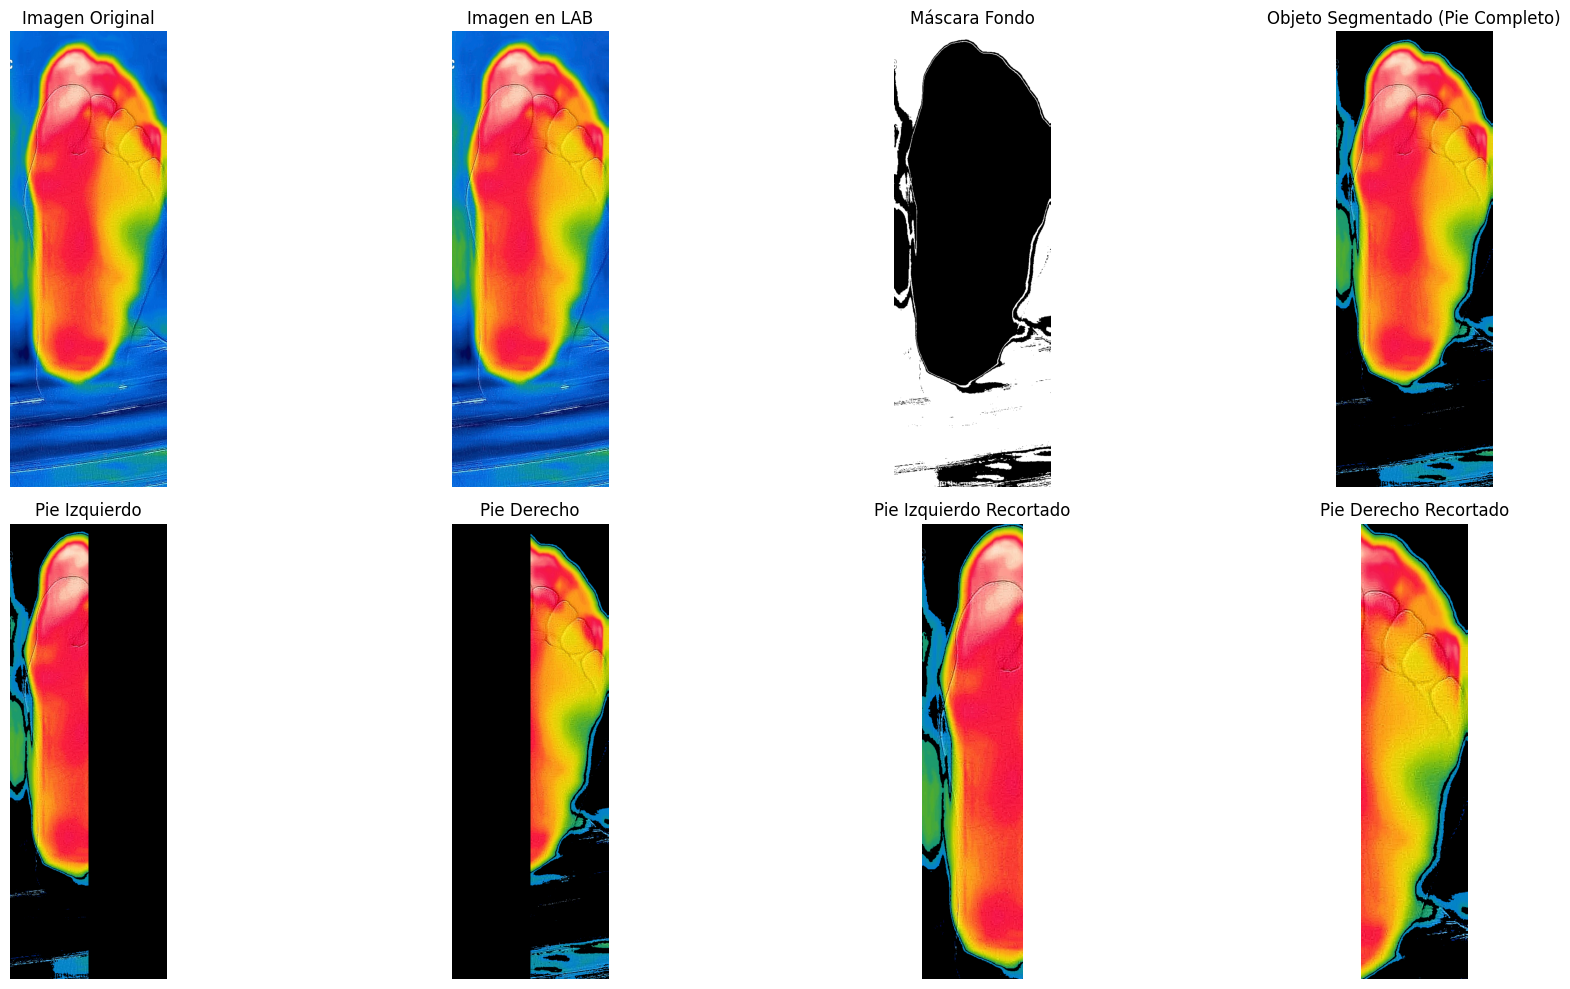

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen
image = cv2.imread('C:/Users/Marben/Documents/segmentacion probar/un solo pie.jpg')

if image is None:
    print("Error al cargar la imagen.")
else:
    # Convertir imagen a RGB para mostrar luego
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convertir imagen a LAB
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)

    # Los canales L, a, b
    L, a, b = cv2.split(lab)

    # Definir rangos para colores de fondo (azul, verde, morado)
    lower_bg1 = np.array([0, 130, 0])
    upper_bg1 = np.array([255, 160, 120])
    lower_bg2 = np.array([0, 90, 110])
    upper_bg2 = np.array([255, 130, 160])

    # Crear máscaras para esos rangos
    mask_bg1 = cv2.inRange(lab, lower_bg1, upper_bg1)
    mask_bg2 = cv2.inRange(lab, lower_bg2, upper_bg2)

    # Combinar máscaras
    mask_background = cv2.bitwise_or(mask_bg1, mask_bg2)

    # Invertir para obtener el objeto (el pie)
    mask_object = cv2.bitwise_not(mask_background)

    # Aplicar máscara para obtener solo el objeto
    object_only = cv2.bitwise_and(image, image, mask=mask_object)

    # === División en pie izquierdo y derecho ===
    coords = cv2.findNonZero(mask_object)
    x, y, w, h = cv2.boundingRect(coords)
    middle = x + w // 2

    mask_left = np.zeros_like(mask_object)
    mask_right = np.zeros_like(mask_object)
    mask_left[y:y+h, x:middle] = mask_object[y:y+h, x:middle]
    mask_right[y:y+h, middle:x+w] = mask_object[y:y+h, middle:x+w]

    foot_left = cv2.bitwise_and(object_only, object_only, mask=mask_left)
    foot_right = cv2.bitwise_and(object_only, object_only, mask=mask_right)

    # === NUEVO: Recorte del área más grande del pie izquierdo ===
    contornos_left, _ = cv2.findContours(mask_left, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contornos_left:
        areas_left = [cv2.contourArea(c) for c in contornos_left]
        max_idx_left = np.argmax(areas_left)
        xL, yL, wL, hL = cv2.boundingRect(contornos_left[max_idx_left])
        foot_left_crop = foot_left[yL:yL+hL, xL:xL+wL]
    else:
        foot_left_crop = np.zeros((50, 50, 3), dtype=np.uint8)

    # === NUEVO: Recorte del área más grande del pie derecho ===
    contornos_right, _ = cv2.findContours(mask_right, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contornos_right:
        areas_right = [cv2.contourArea(c) for c in contornos_right]
        max_idx_right = np.argmax(areas_right)
        xR, yR, wR, hR = cv2.boundingRect(contornos_right[max_idx_right])
        foot_right_crop = foot_right[yR:yR+hR, xR:xR+wR]
    else:
        foot_right_crop = np.zeros((50, 50, 3), dtype=np.uint8)

    # === Mostrar resultados ===
    plt.figure(figsize=(20, 10))

    plt.subplot(2, 4, 1)
    plt.imshow(image_rgb)
    plt.title('Imagen Original')
    plt.axis('off')

    plt.subplot(2, 4, 2)
    plt.imshow(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))
    plt.title('Imagen en LAB')
    plt.axis('off')

    plt.subplot(2, 4, 3)
    plt.imshow(mask_background, cmap='gray')
    plt.title('Máscara Fondo')
    plt.axis('off')

    plt.subplot(2, 4, 4)
    plt.imshow(cv2.cvtColor(object_only, cv2.COLOR_BGR2RGB))
    plt.title('Objeto Segmentado (Pie Completo)')
    plt.axis('off')

    plt.subplot(2, 4, 5)
    plt.imshow(cv2.cvtColor(foot_left, cv2.COLOR_BGR2RGB))
    plt.title('Pie Izquierdo')
    plt.axis('off')

    plt.subplot(2, 4, 6)
    plt.imshow(cv2.cvtColor(foot_right, cv2.COLOR_BGR2RGB))
    plt.title('Pie Derecho')
    plt.axis('off')

    plt.subplot(2, 4, 7)
    plt.imshow(cv2.cvtColor(foot_left_crop, cv2.COLOR_BGR2RGB))
    plt.title('Pie Izquierdo Recortado')
    plt.axis('off')

    plt.subplot(2, 4, 8)
    plt.imshow(cv2.cvtColor(foot_right_crop, cv2.COLOR_BGR2RGB))
    plt.title('Pie Derecho Recortado')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


Se detectaron dos o más objetos.


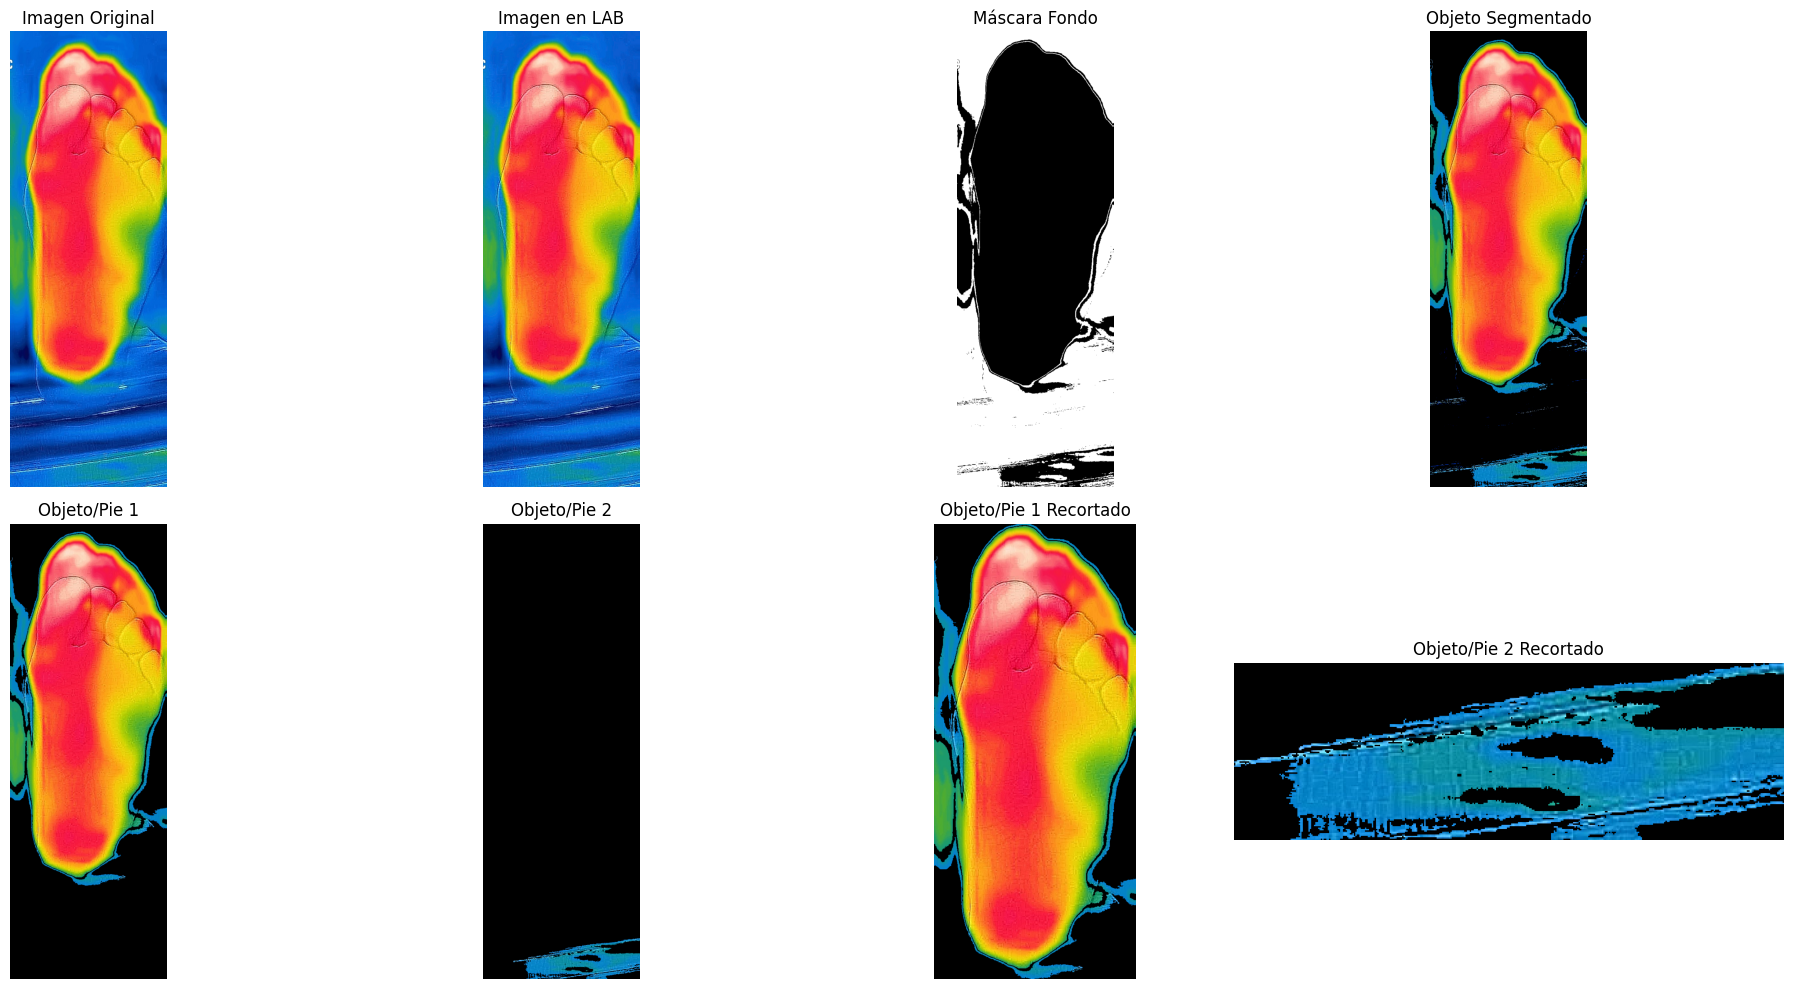

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen
image = cv2.imread('C:/Users/Marben/Documents/segmentacion probar/un solo pie.jpg')

if image is None:
    print("Error al cargar la imagen.")
else:
    # Convertir imagen a RGB para mostrar luego
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convertir imagen a LAB
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)

    # Los canales L, a, b
    L, a, b = cv2.split(lab)

    # Definir rangos para colores de fondo
    lower_bg1 = np.array([0, 130, 0])
    upper_bg1 = np.array([255, 160, 120])
    lower_bg2 = np.array([0, 90, 110])
    upper_bg2 = np.array([255, 130, 160])

    # Crear máscaras para esos rangos
    mask_bg1 = cv2.inRange(lab, lower_bg1, upper_bg1)
    mask_bg2 = cv2.inRange(lab, lower_bg2, upper_bg2)

    # Combinar máscaras
    mask_background = cv2.bitwise_or(mask_bg1, mask_bg2)

    # Invertir para obtener el objeto
    mask_object = cv2.bitwise_not(mask_background)

    # Aplicar máscara para obtener solo el objeto
    object_only = cv2.bitwise_and(image, image, mask=mask_object)

    # =========================================================
    # DETECCIÓN DE OBJETOS
    # =========================================================

    # Encontrar contornos externos de los objetos segmentados
    contornos, _ = cv2.findContours(
        mask_object,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Obtener el área de cada contorno
    areas = [cv2.contourArea(c) for c in contornos]

    # Umbral de área mínima para eliminar objetos pequeños
    area_minima = 1000

    # Conservar solamente objetos suficientemente grandes
    contornos_grandes = [
        c for c in contornos
        if cv2.contourArea(c) >= area_minima
    ]

    # Ordenar los objetos de mayor a menor área
    contornos_grandes = sorted(
        contornos_grandes,
        key=cv2.contourArea,
        reverse=True
    )

    # =========================================================
    # CASO 1: UN SOLO OBJETO GRANDE
    # =========================================================

    if len(contornos_grandes) == 1:

        print("Se detectó un solo objeto.")

        contorno = contornos_grandes[0]

        # Obtener cuadro delimitador
        x, y, w, h = cv2.boundingRect(contorno)

        # Recortar el objeto completo
        objeto_recortado = object_only[y:y+h, x:x+w]

        # En este caso no se divide el objeto
        foot_left = objeto_recortado
        foot_right = np.zeros((50, 50, 3), dtype=np.uint8)

        foot_left_crop = objeto_recortado
        foot_right_crop = np.zeros((50, 50, 3), dtype=np.uint8)

    # =========================================================
    # CASO 2: DOS O MÁS OBJETOS GRANDES
    # =========================================================

    elif len(contornos_grandes) >= 2:

        print("Se detectaron dos o más objetos.")

        # Tomar los dos objetos de mayor área
        contorno_left = contornos_grandes[0]
        contorno_right = contornos_grandes[1]

        # Obtener cuadros delimitadores
        xL, yL, wL, hL = cv2.boundingRect(contorno_left)
        xR, yR, wR, hR = cv2.boundingRect(contorno_right)

        # Crear máscaras individuales
        mask_left = np.zeros_like(mask_object)
        mask_right = np.zeros_like(mask_object)

        cv2.drawContours(
            mask_left,
            [contorno_left],
            -1,
            255,
            thickness=cv2.FILLED
        )

        cv2.drawContours(
            mask_right,
            [contorno_right],
            -1,
            255,
            thickness=cv2.FILLED
        )

        # Obtener cada pie
        foot_left = cv2.bitwise_and(
            object_only,
            object_only,
            mask=mask_left
        )

        foot_right = cv2.bitwise_and(
            object_only,
            object_only,
            mask=mask_right
        )

        # Recortar cada pie
        foot_left_crop = foot_left[yL:yL+hL, xL:xL+wL]
        foot_right_crop = foot_right[yR:yR+hR, xR:xR+wR]

        # Para mostrar el objeto completo
        objeto_recortado = object_only

    # =========================================================
    # CASO 3: NO SE DETECTÓ NINGÚN OBJETO
    # =========================================================

    else:

        print("No se detectaron objetos suficientemente grandes.")

        objeto_recortado = np.zeros(
            (50, 50, 3),
            dtype=np.uint8
        )

        foot_left = objeto_recortado
        foot_right = objeto_recortado

        foot_left_crop = objeto_recortado
        foot_right_crop = objeto_recortado

    # =========================================================
    # MOSTRAR RESULTADOS
    # =========================================================

    plt.figure(figsize=(20, 10))

    plt.subplot(2, 4, 1)
    plt.imshow(image_rgb)
    plt.title('Imagen Original')
    plt.axis('off')

    plt.subplot(2, 4, 2)
    plt.imshow(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))
    plt.title('Imagen en LAB')
    plt.axis('off')

    plt.subplot(2, 4, 3)
    plt.imshow(mask_background, cmap='gray')
    plt.title('Máscara Fondo')
    plt.axis('off')

    plt.subplot(2, 4, 4)
    plt.imshow(cv2.cvtColor(object_only, cv2.COLOR_BGR2RGB))
    plt.title('Objeto Segmentado')
    plt.axis('off')

    plt.subplot(2, 4, 5)
    plt.imshow(cv2.cvtColor(foot_left, cv2.COLOR_BGR2RGB))
    plt.title('Objeto/Pie 1')
    plt.axis('off')

    plt.subplot(2, 4, 6)
    plt.imshow(cv2.cvtColor(foot_right, cv2.COLOR_BGR2RGB))
    plt.title('Objeto/Pie 2')
    plt.axis('off')

    plt.subplot(2, 4, 7)
    plt.imshow(cv2.cvtColor(foot_left_crop, cv2.COLOR_BGR2RGB))
    plt.title('Objeto/Pie 1 Recortado')
    plt.axis('off')

    plt.subplot(2, 4, 8)
    plt.imshow(cv2.cvtColor(foot_right_crop, cv2.COLOR_BGR2RGB))
    plt.title('Objeto/Pie 2 Recortado')
    plt.axis('off')

    plt.tight_layout()
    plt.show()



Se detectó un solo objeto grande.
No se realizó división izquierda/derecha.


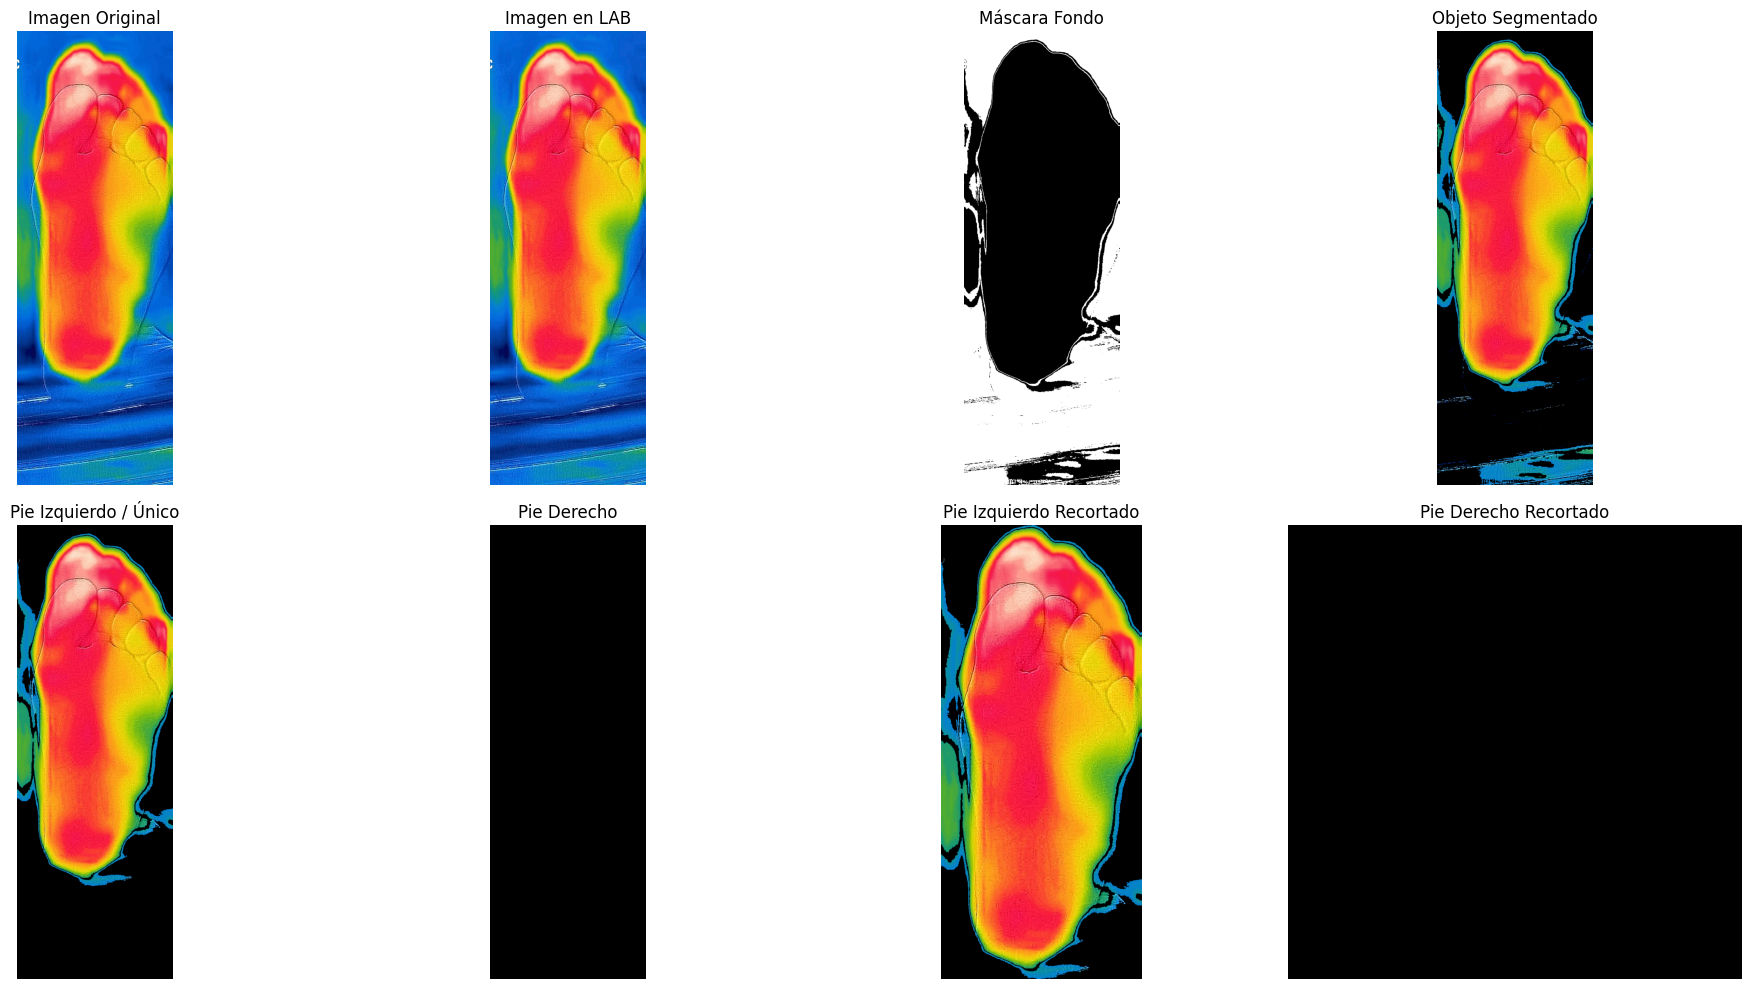

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen
image = cv2.imread(
    'C:/Users/Marben/Documents/segmentacion probar/un solo pie.jpg'
)

if image is None:
    print("Error al cargar la imagen.")

else:
    # ============================================================
    # 1. Convertir la imagen a RGB para visualización
    # ============================================================
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # ============================================================
    # 2. Convertir imagen a espacio de color LAB
    # ============================================================
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)

    # Separar canales L, a y b
    L, a, b = cv2.split(lab)

    # ============================================================
    # 3. Definir rangos de colores correspondientes al fondo
    # ============================================================
    lower_bg1 = np.array([0, 130, 0])
    upper_bg1 = np.array([255, 160, 120])

    lower_bg2 = np.array([0, 90, 110])
    upper_bg2 = np.array([255, 130, 160])

    # Crear máscaras para los rangos del fondo
    mask_bg1 = cv2.inRange(lab, lower_bg1, upper_bg1)
    mask_bg2 = cv2.inRange(lab, lower_bg2, upper_bg2)

    # Combinar máscaras del fondo
    mask_background = cv2.bitwise_or(mask_bg1, mask_bg2)

    # ============================================================
    # 4. Obtener la máscara del objeto (pie)
    # ============================================================
    mask_object = cv2.bitwise_not(mask_background)

    # Aplicar la máscara a la imagen original
    object_only = cv2.bitwise_and(
        image,
        image,
        mask=mask_object
    )

    # ============================================================
    # 5. Detectar objetos mediante contornos
    # ============================================================
    contornos, _ = cv2.findContours(
        mask_object,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Calcular áreas de los contornos
    areas = [cv2.contourArea(c) for c in contornos]

    # ============================================================
    # 6. Seleccionar objetos utilizando un criterio relativo
    # ============================================================

    # Máscaras vacías para los dos pies
    mask_left = np.zeros_like(mask_object)
    mask_right = np.zeros_like(mask_object)

    # Imágenes vacías para los resultados
    foot_left = np.zeros_like(image)
    foot_right = np.zeros_like(image)

    # Recortes iniciales
    foot_left_crop = np.zeros((50, 50, 3), dtype=np.uint8)
    foot_right_crop = np.zeros((50, 50, 3), dtype=np.uint8)

    if len(contornos) > 0:

        # --------------------------------------------------------
        # Ordenar contornos de mayor a menor área
        # --------------------------------------------------------
        indices = np.argsort(areas)[::-1]

        contornos_ordenados = [
            contornos[i] for i in indices
        ]

        areas_ordenadas = [
            areas[i] for i in indices
        ]

        # El objeto más grande se toma como referencia
        area_mayor = areas_ordenadas[0]

        # --------------------------------------------------------
        # Un segundo objeto debe tener al menos el 50 %
        # del área del objeto más grande
        # --------------------------------------------------------
        relacion_minima = 0.50

        contornos_validos = []

        for contorno, area in zip(
            contornos_ordenados,
            areas_ordenadas
        ):

            if area >= area_mayor * relacion_minima:
                contornos_validos.append(contorno)

        # --------------------------------------------------------
        # Limitar a máximo dos objetos
        # --------------------------------------------------------
        contornos_validos = contornos_validos[:2]

        # ========================================================
        # 7. Si solamente se detecta un objeto grande
        # ========================================================
        if len(contornos_validos) == 1:

            contorno = contornos_validos[0]

            # Crear máscara del único pie
            cv2.drawContours(
                mask_left,
                [contorno],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # Obtener el pie segmentado
            foot_left = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_left
            )

            # Obtener bounding box
            x, y, w, h = cv2.boundingRect(contorno)

            # Recortar el único pie
            foot_left_crop = foot_left[
                y:y+h,
                x:x+w
            ]

            print("Se detectó un solo objeto grande.")
            print("No se realizó división izquierda/derecha.")

        # ========================================================
        # 8. Si se detectan dos objetos grandes
        # ========================================================
        elif len(contornos_validos) == 2:

            # ----------------------------------------------------
            # Ordenar los dos objetos según su posición horizontal
            # ----------------------------------------------------
            datos = []

            for contorno in contornos_validos:

                x, y, w, h = cv2.boundingRect(contorno)

                datos.append(
                    (x, y, w, h, contorno)
                )

            # Menor x = lado izquierdo de la imagen
            datos.sort(key=lambda elemento: elemento[0])

            # Primer objeto = izquierdo
            xL, yL, wL, hL, contorno_left = datos[0]

            # Segundo objeto = derecho
            xR, yR, wR, hR, contorno_right = datos[1]

            # ----------------------------------------------------
            # Crear máscara del pie izquierdo
            # ----------------------------------------------------
            cv2.drawContours(
                mask_left,
                [contorno_left],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # ----------------------------------------------------
            # Crear máscara del pie derecho
            # ----------------------------------------------------
            cv2.drawContours(
                mask_right,
                [contorno_right],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # ----------------------------------------------------
            # Obtener cada pie segmentado
            # ----------------------------------------------------
            foot_left = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_left
            )

            foot_right = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_right
            )

            # ----------------------------------------------------
            # Recortar pie izquierdo
            # ----------------------------------------------------
            foot_left_crop = foot_left[
                yL:yL+hL,
                xL:xL+wL
            ]

            # ----------------------------------------------------
            # Recortar pie derecho
            # ----------------------------------------------------
            foot_right_crop = foot_right[
                yR:yR+hR,
                xR:xR+wR
            ]

            print("Se detectaron dos objetos grandes.")
            print("Se identificaron como pie izquierdo y derecho.")

        # ========================================================
        # 9. Si no se detectan objetos válidos
        # ========================================================
        else:

            print("No se detectaron objetos suficientemente grandes.")

    else:

        print("No se encontraron contornos.")

    # ============================================================
    # 10. Mostrar resultados
    # ============================================================
    plt.figure(figsize=(20, 10))

    # Imagen original
    plt.subplot(2, 4, 1)
    plt.imshow(image_rgb)
    plt.title('Imagen Original')
    plt.axis('off')

    # Imagen LAB
    plt.subplot(2, 4, 2)
    plt.imshow(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))
    plt.title('Imagen en LAB')
    plt.axis('off')

    # Máscara del fondo
    plt.subplot(2, 4, 3)
    plt.imshow(mask_background, cmap='gray')
    plt.title('Máscara Fondo')
    plt.axis('off')

    # Objeto segmentado
    plt.subplot(2, 4, 4)
    plt.imshow(
        cv2.cvtColor(
            object_only,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title('Objeto Segmentado')
    plt.axis('off')

    # Pie izquierdo
    plt.subplot(2, 4, 5)
    plt.imshow(
        cv2.cvtColor(
            foot_left,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title('Pie Izquierdo / Único')
    plt.axis('off')

    # Pie derecho
    plt.subplot(2, 4, 6)
    plt.imshow(
        cv2.cvtColor(
            foot_right,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title('Pie Derecho')
    plt.axis('off')

    # Pie izquierdo recortado
    plt.subplot(2, 4, 7)
    plt.imshow(
        cv2.cvtColor(
            foot_left_crop,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title('Pie Izquierdo Recortado')
    plt.axis('off')

    # Pie derecho recortado
    plt.subplot(2, 4, 8)
    plt.imshow(
        cv2.cvtColor(
            foot_right_crop,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title('Pie Derecho Recortado')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

Se detectaron dos objetos grandes.
Ambos objetos cumplen el criterio del 50 %.


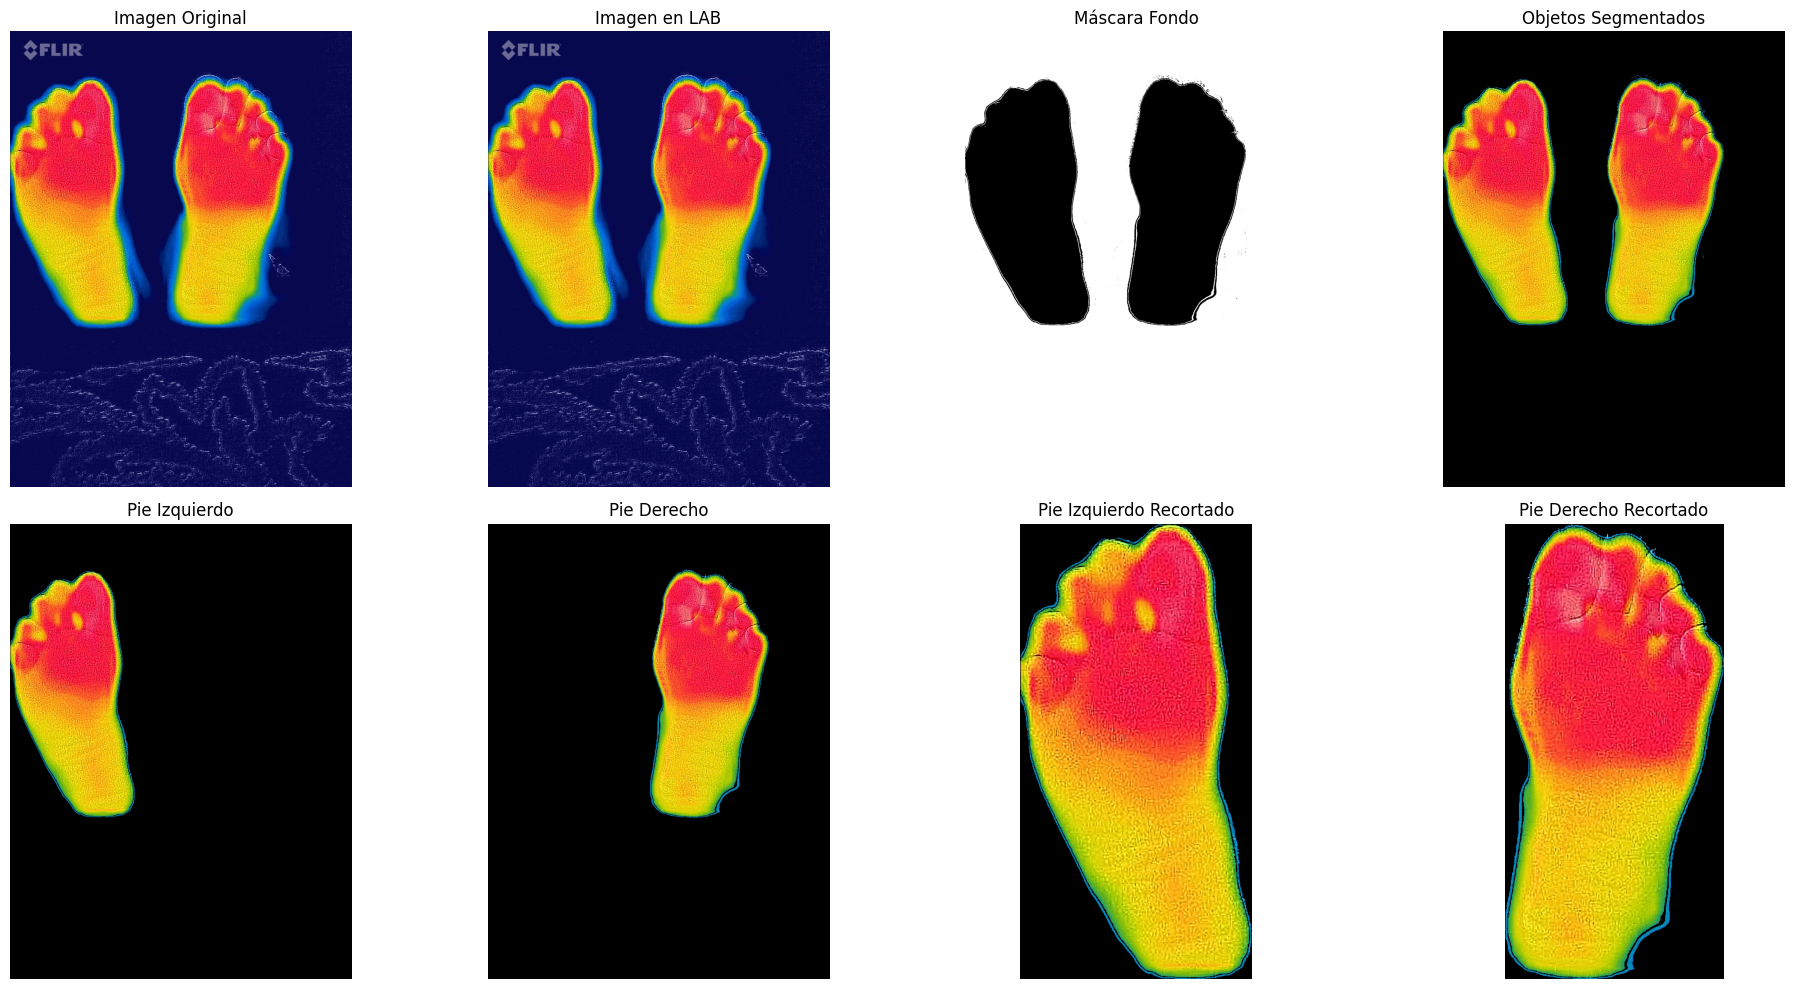

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen
image = cv2.imread(
   'C:/Users/Marben/Desktop/Inferencias/IDM03/Zuly nuevas imagenes/FLIR_20250406_105754_186.jpg'
)

if image is None:
    print("Error al cargar la imagen.")

else:
    # ============================================================
    # 1. Convertir la imagen a RGB para visualización
    # ============================================================
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # ============================================================
    # 2. Convertir imagen a espacio de color LAB
    # ============================================================
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2Lab)

    # Separar canales L, a y b
    L, a, b = cv2.split(lab)

    # ============================================================
    # 3. Definir rangos de colores correspondientes al fondo
    # ============================================================
    lower_bg1 = np.array([0, 130, 0])
    upper_bg1 = np.array([255, 160, 120])

    lower_bg2 = np.array([0, 90, 110])
    upper_bg2 = np.array([255, 130, 160])

    # Crear máscaras para los rangos del fondo
    mask_bg1 = cv2.inRange(lab, lower_bg1, upper_bg1)
    mask_bg2 = cv2.inRange(lab, lower_bg2, upper_bg2)

    # Combinar máscaras del fondo
    mask_background = cv2.bitwise_or(mask_bg1, mask_bg2)

    # ============================================================
    # 4. Obtener la máscara del objeto
    # ============================================================
    mask_object = cv2.bitwise_not(mask_background)

    # Aplicar la máscara a la imagen original
    object_only = cv2.bitwise_and(
        image,
        image,
        mask=mask_object
    )

    # ============================================================
    # 5. Detectar objetos mediante contornos
    # ============================================================
    contornos, _ = cv2.findContours(
        mask_object,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Calcular áreas
    areas = [cv2.contourArea(c) for c in contornos]

    # ============================================================
    # 6. Inicializar variables
    # ============================================================

    mask_left = np.zeros_like(mask_object)
    mask_right = np.zeros_like(mask_object)

    foot_left = np.zeros_like(image)
    foot_right = np.zeros_like(image)

    foot_left_crop = None
    foot_right_crop = None

    numero_pies = 0

    # ============================================================
    # 7. Seleccionar objetos utilizando el criterio del 50 %
    # ============================================================

    if len(contornos) > 0:

        # Ordenar contornos de mayor a menor área
        indices = np.argsort(areas)[::-1]

        contornos_ordenados = [
            contornos[i] for i in indices
        ]

        areas_ordenadas = [
            areas[i] for i in indices
        ]

        # Área del objeto más grande
        area_mayor = areas_ordenadas[0]

        # ========================================================
        # Criterio:
        # Un segundo objeto debe tener al menos el 50 %
        # del área del objeto más grande
        # ========================================================
        relacion_minima = 0.50

        contornos_validos = []

        for contorno, area in zip(
            contornos_ordenados,
            areas_ordenadas
        ):

            if area >= area_mayor * relacion_minima:
                contornos_validos.append(contorno)

        # Como máximo se consideran dos objetos
        contornos_validos = contornos_validos[:2]

        # ========================================================
        # CASO 1: SOLO SE DETECTA UN OBJETO GRANDE
        # ========================================================

        if len(contornos_validos) == 1:

            numero_pies = 1

            contorno = contornos_validos[0]

            # Crear máscara del objeto
            cv2.drawContours(
                mask_left,
                [contorno],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # Obtener objeto segmentado
            foot_left = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_left
            )

            # Obtener bounding box
            x, y, w, h = cv2.boundingRect(contorno)

            # Recortar solamente el objeto detectado
            foot_left_crop = foot_left[
                y:y+h,
                x:x+w
            ]

            print("Se detectó un solo objeto grande.")
            print("No se realizó división izquierda/derecha.")

        # ========================================================
        # CASO 2: SE DETECTAN DOS OBJETOS GRANDES
        # ========================================================

        elif len(contornos_validos) == 2:

            numero_pies = 2

            datos = []

            for contorno in contornos_validos:

                x, y, w, h = cv2.boundingRect(contorno)

                datos.append(
                    (x, y, w, h, contorno)
                )

            # Ordenar por posición horizontal
            datos.sort(key=lambda elemento: elemento[0])

            # Objeto izquierdo
            xL, yL, wL, hL, contorno_left = datos[0]

            # Objeto derecho
            xR, yR, wR, hR, contorno_right = datos[1]

            # ----------------------------------------------------
            # Máscara del objeto izquierdo
            # ----------------------------------------------------
            cv2.drawContours(
                mask_left,
                [contorno_left],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # ----------------------------------------------------
            # Máscara del objeto derecho
            # ----------------------------------------------------
            cv2.drawContours(
                mask_right,
                [contorno_right],
                -1,
                255,
                thickness=cv2.FILLED
            )

            # ----------------------------------------------------
            # Obtener objetos segmentados
            # ----------------------------------------------------
            foot_left = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_left
            )

            foot_right = cv2.bitwise_and(
                object_only,
                object_only,
                mask=mask_right
            )

            # ----------------------------------------------------
            # Recortar objeto izquierdo
            # ----------------------------------------------------
            foot_left_crop = foot_left[
                yL:yL+hL,
                xL:xL+wL
            ]

            # ----------------------------------------------------
            # Recortar objeto derecho
            # ----------------------------------------------------
            foot_right_crop = foot_right[
                yR:yR+hR,
                xR:xR+wR
            ]

            print("Se detectaron dos objetos grandes.")
            print("Ambos objetos cumplen el criterio del 50 %.")

        # ========================================================
        # CASO 3: NO HAY OBJETOS VÁLIDOS
        # ========================================================

        else:

            print("No se detectaron objetos suficientemente grandes.")

    else:

        print("No se encontraron contornos.")

    # ============================================================
    # 8. VISUALIZACIÓN
    # ============================================================

    # ------------------------------------------------------------
    # CASO DE UN SOLO PIE
    # ------------------------------------------------------------
    if numero_pies == 1:

        plt.figure(figsize=(16, 8))

        # Imagen original
        plt.subplot(2, 3, 1)
        plt.imshow(image_rgb)
        plt.title('Imagen Original')
        plt.axis('off')

        # Imagen LAB
        plt.subplot(2, 3, 2)
        plt.imshow(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))
        plt.title('Imagen en LAB')
        plt.axis('off')

        # Máscara del fondo
        plt.subplot(2, 3, 3)
        plt.imshow(mask_background, cmap='gray')
        plt.title('Máscara Fondo')
        plt.axis('off')

        # Objeto segmentado
        plt.subplot(2, 3, 4)
        plt.imshow(
            cv2.cvtColor(
                foot_left,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Objeto Detectado')
        plt.axis('off')

        # Recorte
        plt.subplot(2, 3, 5)
        plt.imshow(
            cv2.cvtColor(
                foot_left_crop,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Objeto Recortado')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

    # ------------------------------------------------------------
    # CASO DE DOS PIES
    # ------------------------------------------------------------
    elif numero_pies == 2:

        plt.figure(figsize=(20, 10))

        # Imagen original
        plt.subplot(2, 4, 1)
        plt.imshow(image_rgb)
        plt.title('Imagen Original')
        plt.axis('off')

        # Imagen LAB
        plt.subplot(2, 4, 2)
        plt.imshow(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))
        plt.title('Imagen en LAB')
        plt.axis('off')

        # Máscara del fondo
        plt.subplot(2, 4, 3)
        plt.imshow(mask_background, cmap='gray')
        plt.title('Máscara Fondo')
        plt.axis('off')

        # Objeto segmentado completo
        plt.subplot(2, 4, 4)
        plt.imshow(
            cv2.cvtColor(
                object_only,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Objetos Segmentados')
        plt.axis('off')

        # Pie izquierdo
        plt.subplot(2, 4, 5)
        plt.imshow(
            cv2.cvtColor(
                foot_left,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Pie Izquierdo')
        plt.axis('off')

        # Pie derecho
        plt.subplot(2, 4, 6)
        plt.imshow(
            cv2.cvtColor(
                foot_right,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Pie Derecho')
        plt.axis('off')

        # Pie izquierdo recortado
        plt.subplot(2, 4, 7)
        plt.imshow(
            cv2.cvtColor(
                foot_left_crop,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Pie Izquierdo Recortado')
        plt.axis('off')

        # Pie derecho recortado
        plt.subplot(2, 4, 8)
        plt.imshow(
            cv2.cvtColor(
                foot_right_crop,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Pie Derecho Recortado')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

    # ------------------------------------------------------------
    # CASO SIN OBJETOS
    # ------------------------------------------------------------
    else:

        plt.figure(figsize=(12, 6))

        plt.subplot(1, 3, 1)
        plt.imshow(image_rgb)
        plt.title('Imagen Original')
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(mask_background, cmap='gray')
        plt.title('Máscara Fondo')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(
            cv2.cvtColor(
                object_only,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title('Objeto Segmentado')
        plt.axis('off')

        plt.tight_layout()
        plt.show()